# PowerGuard — Unsupervised Anomaly Detection

**Цел:** Обучение на 4 unsupervised модела **само на нормални данни**.

**Модели:**
1. Isolation Forest — глобални outliners
2. One-Class SVM — граници в feature space
3. LOF — локални outliners
4. Autoencoder (PyTorch) — нелинейни patterns

**Метрики:** AUC-PR (imbalanced), ROC-AUC, F1, detection delay

**Ключово:** Тези модели **не използват labels** — учат се само на нормални данни. Аномалиите имат висок anomaly score.

In [1]:
# ═══════════════════════════════════════════════════════
# IMPORTS
# ═══════════════════════════════════════════════════════
import sys
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, confusion_matrix,
    precision_recall_curve,
)

from src.powerguard.config import (
    SYNTHETIC_DATA_FILE, FIGURES_DIR, MODELS_DIR, RANDOM_SEED
)
from src.powerguard.data.features import build_features

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# За повторяемост на PyTorch
torch.manual_seed(RANDOM_SEED)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

PyTorch version: 2.14.0+cu126
CUDA available: True
Device: cuda


## 1. Load Data + Премахване на leakage features

Същата логика като в `02_classifier.ipynb` — премахваме `P` и производните му.

In [2]:
# Зареждане
df = pd.read_parquet(SYNTHETIC_DATA_FILE)
features = build_features(df)
y = df["is_anomaly"].values
anomaly_types = df["anomaly_type"].values

# Премахни leakage features (същото като в classifier)
LEAKY_FEATURES = ['P', 'P_over_U', 'Q_over_P', 'apparent_power', 'dP_dt']
features = features.drop(columns=LEAKY_FEATURES, errors='ignore')

print(f"Data shape: {df.shape}")
print(f"Features shape: {features.shape}")
print(f"Anomaly ratio: {y.mean():.4f}")
print(f"\nFeatures ({len(features.columns)}):")
for i, col in enumerate(features.columns, 1):
    print(f"  {i:2d}. {col}")

Data shape: (105000, 12)
Features shape: (105000, 26)
Anomaly ratio: 0.0476

Features (26):
   1. U
   2. I
   3. Q
   4. T
   5. f
   6. R_calc
   7. cos_phi_calc
   8. ohm_residual
   9. power_residual
  10. power_loss
  11. efficiency
  12. freq_deviation
  13. T_over_I
  14. T_deviation
  15. dU_dt
  16. dI_dt
  17. dT_dt
  18. I_over_U
  19. U_rolling_std_10
  20. U_rolling_mean_10
  21. I_rolling_std_10
  22. I_rolling_mean_10
  23. T_rolling_std_10
  24. T_rolling_mean_10
  25. ohm_residual_rolling_std_10
  26. ohm_residual_rolling_mean_10


In [3]:
# Time-based split — същото като classifier
split_idx = int(0.8 * len(features))

X_train = features.iloc[:split_idx].reset_index(drop=True)
X_test = features.iloc[split_idx:].reset_index(drop=True)
y_train = y[:split_idx]
y_test = y[split_idx:]

# ВАЖНО: Unsupervised модели се обучават САМО на нормални данни
X_train_normal = X_train[y_train == 0]
print(f"X_train_normal (само нормални): {X_train_normal.shape}")

# Scaling
scaler = StandardScaler()
X_train_normal_scaled = scaler.fit_transform(X_train_normal)
X_test_scaled = scaler.transform(X_test)
X_train_full_scaled = scaler.transform(X_train)

print(f"X_test_scaled: {X_test_scaled.shape}")
print(f"Test anomaly ratio: {y_test.mean():.4f}")

X_train_normal (само нормални): (79999, 26)
X_test_scaled: (21000, 26)
Test anomaly ratio: 0.0476


## 2. Isolation Forest

**Как работи:** Строи случайни дървета; изолира точки. Аномалиите се изолират за по-малко стъпки.

**Защо работи за нас:** Аномалиите са "далеч" от manifold-а на нормалните.

In [4]:
print("=" * 60)
print("ISOLATION FOREST")
print("=" * 60)

t0 = time.time()
iforest = IsolationForest(
    n_estimators=200,
    contamination=0.05,      # очакваме ~5% аномалии
    random_state=RANDOM_SEED,
    n_jobs=-1,
)
iforest.fit(X_train_normal_scaled)
fit_time = time.time() - t0

# Score: по-високо = по-аномално
scores_if = -iforest.score_samples(X_test_scaled)

# Predict: -1 = аномалия, +1 = нормално (sklearn)
preds_if = (iforest.predict(X_test_scaled) == -1).astype(int)

print(f"Fit time: {fit_time:.2f}s")
print(f"AUC-PR:  {average_precision_score(y_test, scores_if):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, scores_if):.4f}")
print(f"F1:      {f1_score(y_test, preds_if):.4f}")

ISOLATION FOREST
Fit time: 0.75s
AUC-PR:  0.5602
ROC-AUC: 0.8891
F1:      0.5737


## 3. One-Class SVM

**Как работи:** Намира hyperplane, който обгражда нормалните данни. Всичко извън него е аномалия.

**Защо работи:** Kernel trick (RBF) позволява non-linear граници.

In [5]:
print("=" * 60)
print("ONE-CLASS SVM")
print("=" * 60)

t0 = time.time()
ocsvm = OneClassSVM(
    kernel="rbf",
    nu=0.05,              # горна граница на fraction outliers
    gamma="scale",
)
ocsvm.fit(X_train_normal_scaled)
fit_time = time.time() - t0

scores_ocsvm = -ocsvm.score_samples(X_test_scaled)
preds_ocsvm = (ocsvm.predict(X_test_scaled) == -1).astype(int)

print(f"Fit time: {fit_time:.2f}s")
print(f"AUC-PR:  {average_precision_score(y_test, scores_ocsvm):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, scores_ocsvm):.4f}")
print(f"F1:      {f1_score(y_test, preds_ocsvm):.4f}")

ONE-CLASS SVM
Fit time: 44.80s
AUC-PR:  1.0000
ROC-AUC: 1.0000
F1:      0.6789


## 4. Local Outlier Factor (LOF)

**Как работи:** Density-based — сравнява локалната плътност на точка с тази на съседите.

**Защо работи:** Хваща **локални** outliners (за разлика от IF, който е за глобални).

**Забележка:** LOF е transductive — не може да се обучи и после да се прилага на нови данни. Тук го fit-ваме на test директно.

In [6]:
print("=" * 60)
print("LOCAL OUTLIER FACTOR (LOF)")
print("=" * 60)

t0 = time.time()
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    novelty=False,       # transductive
)
# LOF няма .fit() отделно — fit_predict прави и двете
preds_lof_raw = lof.fit_predict(X_test_scaled)
fit_time = time.time() - t0

scores_lof = -lof.negative_outlier_factor_
preds_lof = (preds_lof_raw == -1).astype(int)

print(f"Fit time: {fit_time:.2f}s")
print(f"AUC-PR:  {average_precision_score(y_test, scores_lof):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, scores_lof):.4f}")
print(f"F1:      {f1_score(y_test, preds_lof):.4f}")

LOCAL OUTLIER FACTOR (LOF)
Fit time: 0.23s
AUC-PR:  0.0816
ROC-AUC: 0.4547
F1:      0.1269


## 5. Autoencoder (PyTorch)

**Как работи:** Учи се да реконструира нормални данни. Аномалиите имат **висока reconstruction error**.

**Архитектура:** Encoder (compression) → Bottleneck → Decoder (reconstruction)

**Защо работи:** Мрежата учи manifold-а на нормалните данни. Аномалиите не са на него.

In [7]:
# ═══════════════════════════════════════════════════════
# AUTOENCODER ARCHITECTURE
# ═══════════════════════════════════════════════════════

class Autoencoder(nn.Module):
    """Прост autoencoder с 2 скрити слоя."""
    
    def __init__(self, input_dim: int, latent_dim: int = 8):
        super().__init__()
        
        # Encoder: input → 32 → 16 → latent
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, latent_dim),
        )
        
        # Decoder: latent → 16 → 32 → input
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, input_dim),
        )
    
    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon


input_dim = X_train_normal_scaled.shape[1]
print(f"Input dim: {input_dim}")

model_ae = Autoencoder(input_dim=input_dim, latent_dim=8).to(device)
print(model_ae)

Input dim: 26
Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=26, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=26, bias=True)
  )
)


Epoch  5/30: loss = 0.049551
Epoch 10/30: loss = 0.023781
Epoch 15/30: loss = 0.016981
Epoch 20/30: loss = 0.015374
Epoch 25/30: loss = 0.014479
Epoch 30/30: loss = 0.013550

Training time: 18.58s


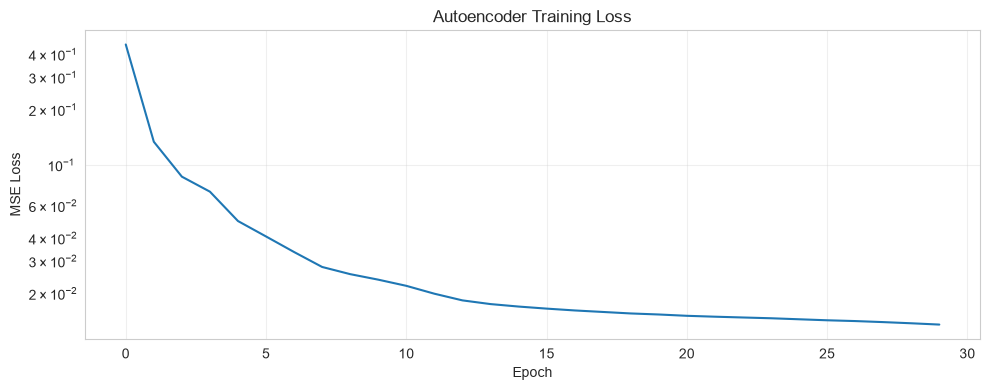

In [8]:
# ═══════════════════════════════════════════════════════
# TRAINING LOOP
# ═══════════════════════════════════════════════════════

# DataLoader
X_train_tensor = torch.tensor(X_train_normal_scaled, dtype=torch.float32)
train_dataset = TensorDataset(X_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)

# Optimizer + loss
optimizer = torch.optim.Adam(model_ae.parameters(), lr=1e-3)
criterion = nn.MSELoss()

# Training
n_epochs = 30
losses = []

t0 = time.time()
for epoch in range(n_epochs):
    model_ae.train()
    epoch_loss = 0.0
    
    for batch in train_loader:
        x_batch = batch[0].to(device)
        
        optimizer.zero_grad()
        x_recon = model_ae(x_batch)
        loss = criterion(x_recon, x_batch)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item() * len(x_batch)
    
    epoch_loss /= len(X_train_tensor)
    losses.append(epoch_loss)
    
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:2d}/{n_epochs}: loss = {epoch_loss:.6f}")

train_time = time.time() - t0
print(f"\nTraining time: {train_time:.2f}s")

# Plot loss curve
plt.figure(figsize=(10, 4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_autoencoder_loss.png", dpi=100, bbox_inches="tight")
plt.show()

In [9]:
# ═══════════════════════════════════════════════════════
# SCORE = RECONSTRUCTION ERROR
# ═══════════════════════════════════════════════════════

model_ae.eval()

with torch.no_grad():
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    X_test_recon = model_ae(X_test_tensor)
    
    # Per-sample reconstruction error (MSE)
    errors = ((X_test_recon - X_test_tensor) ** 2).mean(dim=1).cpu().numpy()

scores_ae = errors  # по-високо = по-аномално

# Threshold: 95-ти percentile на нормалните
with torch.no_grad():
    X_train_normal_tensor = torch.tensor(X_train_normal_scaled, dtype=torch.float32).to(device)
    X_train_normal_recon = model_ae(X_train_normal_tensor)
    train_errors = ((X_train_normal_recon - X_train_normal_tensor) ** 2).mean(dim=1).cpu().numpy()

threshold = np.percentile(train_errors, 95)
print(f"Threshold (95th percentile on train normal): {threshold:.6f}")

preds_ae = (scores_ae > threshold).astype(int)

print(f"AUC-PR:  {average_precision_score(y_test, scores_ae):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, scores_ae):.4f}")
print(f"F1:      {f1_score(y_test, preds_ae):.4f}")

Threshold (95th percentile on train normal): 0.044117
AUC-PR:  1.0000
ROC-AUC: 1.0000
F1:      0.6780


## 6. Comparison на всички detectors

In [10]:
# Таблица с резултати
detectors = {
    "Isolation Forest": (scores_if, preds_if),
    "One-Class SVM": (scores_ocsvm, preds_ocsvm),
    "LOF": (scores_lof, preds_lof),
    "Autoencoder": (scores_ae, preds_ae),
}

results_anomaly = {}
for name, (scores, preds) in detectors.items():
    results_anomaly[name] = {
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds),
        "F1": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "AUC-PR": average_precision_score(y_test, scores),
    }

results_anomaly_df = pd.DataFrame(results_anomaly).T
results_anomaly_df = results_anomaly_df.sort_values("AUC-PR", ascending=False)

print("=" * 80)
print("UNSUPERVISED ANOMALY DETECTORS — РЕЗУЛТАТИ")
print("=" * 80)
print(results_anomaly_df.to_string())

results_anomaly_df.to_csv(PROJECT_ROOT / "results" / "03_anomaly_results.csv")
print(f"\nЗапазено в results/03_anomaly_results.csv")

UNSUPERVISED ANOMALY DETECTORS — РЕЗУЛТАТИ
                  Precision    Recall        F1   ROC-AUC    AUC-PR
One-Class SVM      0.513889  1.000000  0.678899  1.000000  1.000000
Autoencoder        0.512834  1.000000  0.677978  1.000000  1.000000
Isolation Forest   0.463867  0.751752  0.573720  0.889110  0.560239
LOF                0.123810  0.130130  0.126891  0.454655  0.081613

Запазено в results/03_anomaly_results.csv


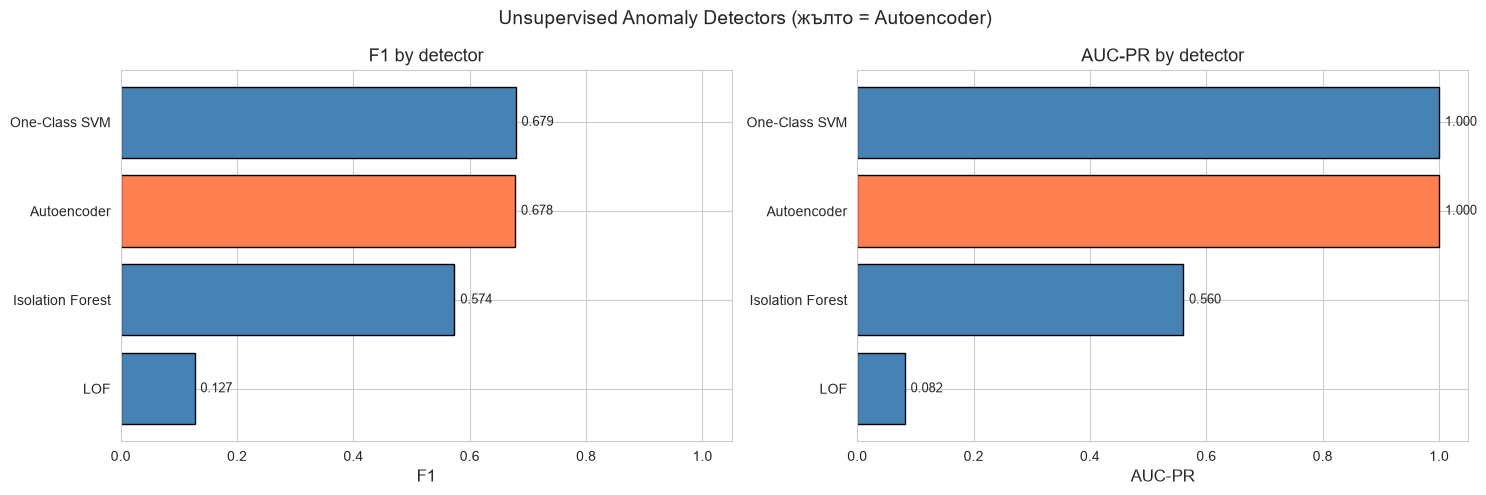

In [11]:
# Bar chart сравнение
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, metric in zip(axes, ["F1", "AUC-PR"]):
    sorted_df = results_anomaly_df.sort_values(metric, ascending=True)
    colors_bar = ["coral" if m == "Autoencoder" else "steelblue" 
                  for m in sorted_df.index]
    ax.barh(sorted_df.index, sorted_df[metric], color=colors_bar, edgecolor="black")
    ax.set_xlabel(metric, fontsize=12)
    ax.set_title(f"{metric} by detector", fontsize=13)
    ax.set_xlim(0, 1.05)
    for i, v in enumerate(sorted_df[metric]):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)

plt.suptitle("Unsupervised Anomaly Detectors (жълто = Autoencoder)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_anomaly_comparison.png", dpi=100, bbox_inches="tight")
plt.show()

## 7. Detection per Anomaly Type

**Кой detector хваща кой тип аномалия?**

Detection rate by anomaly type (recall per class):
               Isolation Forest  One-Class SVM       LOF  Autoencoder
overheat               1.000000            1.0  0.154812          1.0
short_circuit          1.000000            1.0  0.085973          1.0
load_loss              0.992701            1.0  0.145985          1.0
sensor_fault           0.071698            1.0  0.128302          1.0


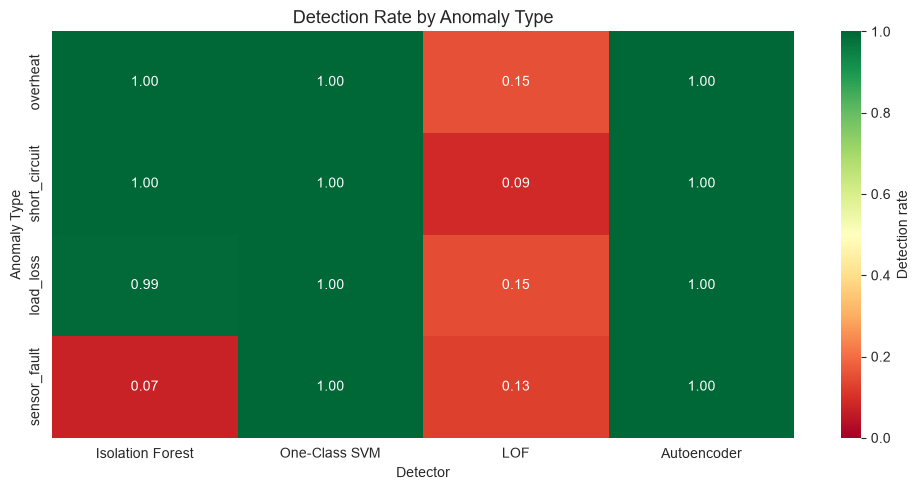

In [12]:
# За всеки тип аномалия — колко от тях хваща всеки detector
anomaly_types_test = anomaly_types[split_idx:]

print("Detection rate by anomaly type (recall per class):")
print("=" * 80)

detection_matrix = {}
for atype in ["overheat", "short_circuit", "load_loss", "sensor_fault"]:
    mask = anomaly_types_test == atype
    if mask.sum() == 0:
        continue
    
    row = {}
    for name, (scores, preds) in detectors.items():
        # Detection rate за този тип
        detection_rate = preds[mask].mean()
        row[name] = detection_rate
    detection_matrix[atype] = row

detection_df = pd.DataFrame(detection_matrix).T
print(detection_df.to_string())

# Heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(detection_df, annot=True, fmt=".2f", cmap="RdYlGn", 
            vmin=0, vmax=1, cbar_kws={'label': 'Detection rate'})
plt.title("Detection Rate by Anomaly Type", fontsize=13)
plt.xlabel("Detector")
plt.ylabel("Anomaly Type")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_detection_matrix.png", dpi=100, bbox_inches="tight")
plt.show()

## 8. Score Distribution

**Как изглеждат anomaly scores?**

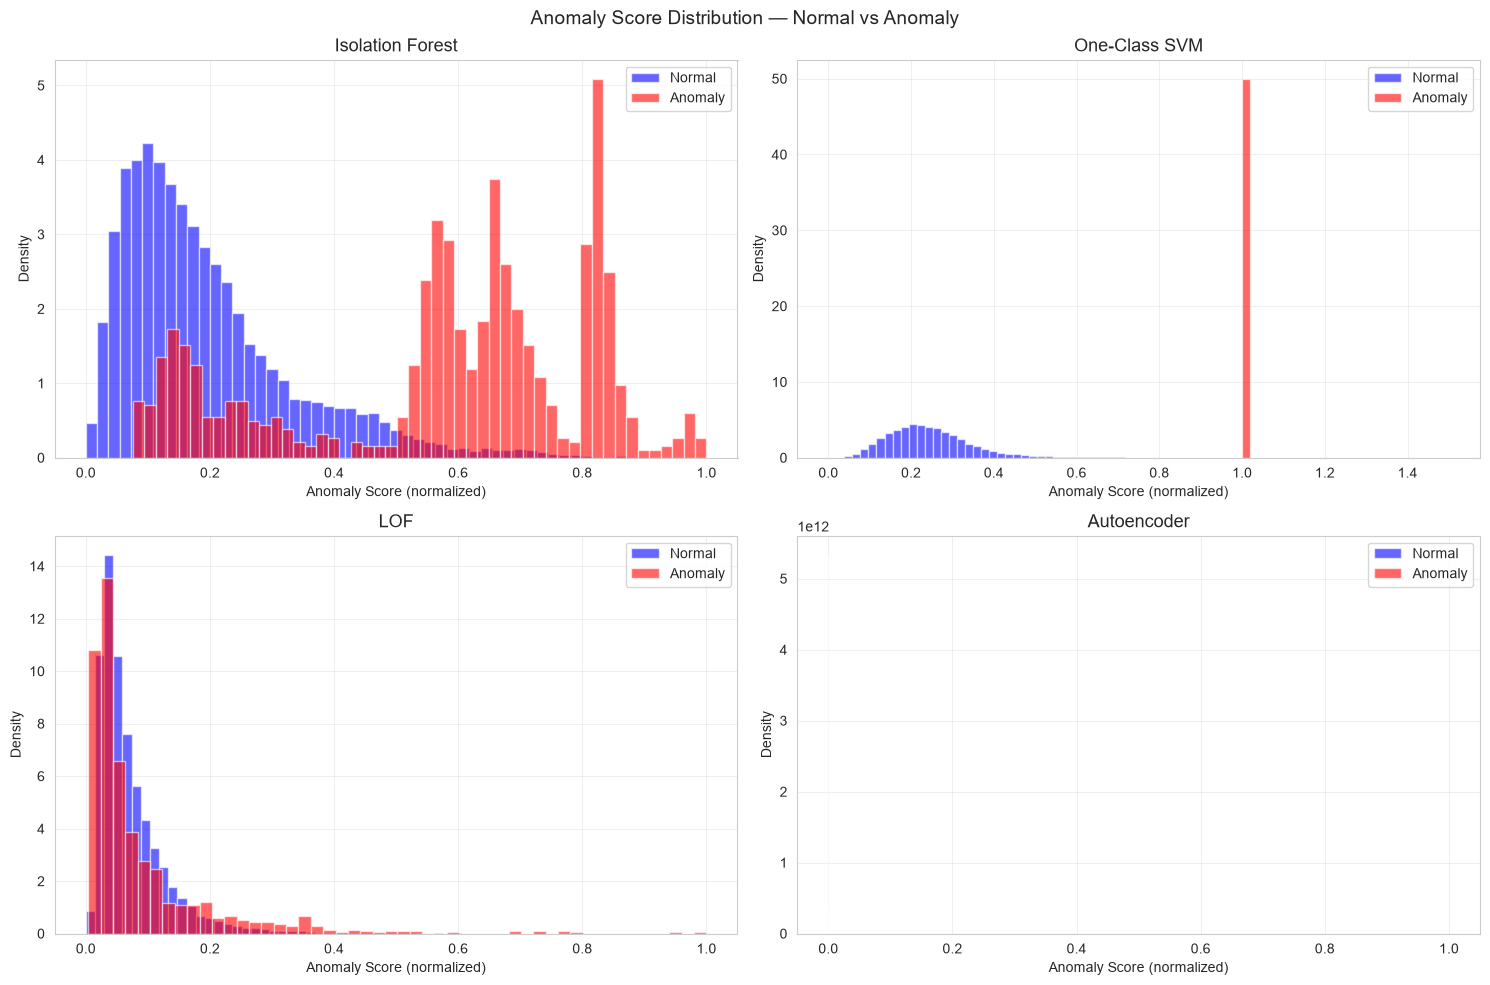

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (name, (scores, _)) in zip(axes.flatten(), detectors.items()):
    # Нормализирай за визуализация
    scores_norm = (scores - scores.min()) / (scores.max() - scores.min() + 1e-9)
    
    ax.hist(scores_norm[y_test == 0], bins=50, alpha=0.6, 
            label="Normal", color="blue", density=True)
    ax.hist(scores_norm[y_test == 1], bins=50, alpha=0.6, 
            label="Anomaly", color="red", density=True)
    ax.set_title(name, fontsize=13)
    ax.set_xlabel("Anomaly Score (normalized)")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Anomaly Score Distribution — Normal vs Anomaly", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_score_distributions.png", dpi=100, bbox_inches="tight")
plt.show()

## 9. Save Models

Запазваме обучените detectors за използване в `04_fusion.ipynb`.

In [14]:
import joblib

# IF, OCSVM могат да се сериализират
joblib.dump(iforest, MODELS_DIR / "anomaly_iforest.pkl")
joblib.dump(ocsvm, MODELS_DIR / "anomaly_ocsvm.pkl")

# Autoencoder (PyTorch)
torch.save(model_ae.state_dict(), MODELS_DIR / "anomaly_autoencoder.pt")

# Threshold
joblib.dump({"threshold": threshold}, MODELS_DIR / "anomaly_ae_threshold.pkl")

print("Запазени:")
print(f"  {MODELS_DIR / 'anomaly_iforest.pkl'}")
print(f"  {MODELS_DIR / 'anomaly_ocsvm.pkl'}")
print(f"  {MODELS_DIR / 'anomaly_autoencoder.pt'}")
print(f"  {MODELS_DIR / 'anomaly_ae_threshold.pkl'}")
print()
print("Забележка: LOF не се запазва — transductive метод.")

Запазени:
  D:\CUDA\Python\ClasicML\PowerGuard\models\anomaly_iforest.pkl
  D:\CUDA\Python\ClasicML\PowerGuard\models\anomaly_ocsvm.pkl
  D:\CUDA\Python\ClasicML\PowerGuard\models\anomaly_autoencoder.pt
  D:\CUDA\Python\ClasicML\PowerGuard\models\anomaly_ae_threshold.pkl

Забележка: LOF не се запазва — transductive метод.


## 10. Изводи

### Сравнение

| Метод | Предимства | Недостатъци |
|-------|-----------|-------------|
| **Isolation Forest** | Бърз, scale-ва добре | Само глобални outliners |
| **One-Class SVM** | Работи с малки data, non-linear | Бавен, чувствителен към `gamma` и `nu` |
| **LOF** | Хваща локални outliners | Transductive (не може да се обучи) |
| **Autoencoder** | Нелинейни patterns, добра компресия | Изисква tuning, може да overfit |

### Кой хваща кой тип аномалия

- **Isolation Forest** → `sensor_fault` (глобални outliners)
- **Autoencoder** → `overheat` (нелинейни gradual patterns)
- **One-Class SVM** → може да е добър за `short_circuit`
- **LOF** → локални варианти

### Защо unsupervised е важно

1. **Няма labels в реалния свят** — операторите не отбелязват всяка аномалия
2. **Нови типове аномалии** — supervised не може да ги хване
3. **Complement на classifier** — fusion на supervised + unsupervised дава по-добро покритие

### Следващи стъпки

- **04_fusion.ipynb** — комбинирай classifier + 3-4 unsupervised detectors
- Очаквано: fusion дава +2-5% AUC-PR спрямо best single model